           date  new_deaths_smoothed_per_million
8435 2023-02-07                        12.875677
8434 2023-02-06                        12.691674
8433 2023-02-05                        12.549956
8432 2023-02-04                        12.335095
8431 2023-02-03                        12.042519
                     min        max  count
country                                   
Brazil          0.000000  83.765490    694
Germany         0.000000  75.596375    833
India           0.000000  66.786520   1238
Japan           0.000000  82.765780    794
South Africa    0.000000  33.727688    479
Sweden          0.000000  72.408060    114
United Kingdom  0.574073  74.430050    602
United States   0.002831  67.529830    878
country
Brazil           2021-09-01
Germany          2021-06-18
India            2021-11-26
Japan            2021-07-28
South Africa     2022-05-27
Sweden           2021-07-04
United Kingdom   2021-05-17
United States    2021-04-23
Name: date, dtype: datetime64[us]
          

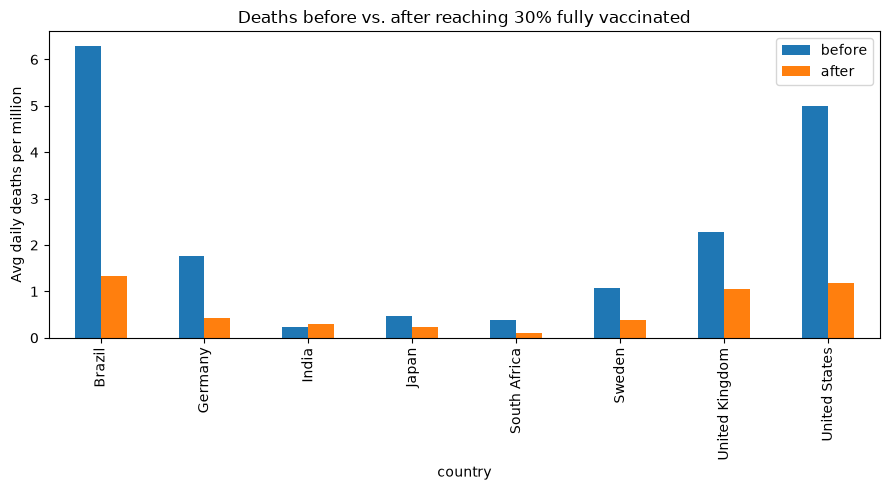

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sub = pd.read_csv("../data/covid_focus.csv", parse_dates=["date"])

# 1. Inspect the Japan spike: top 5 values and their dates
jp = sub[sub["country"] == "Japan"][["date", "new_deaths_smoothed_per_million"]]
print(jp.nlargest(5, "new_deaths_smoothed_per_million"))

# 2. Cut each country off at its last real reporting date (max 2023-06-30)
END = pd.Timestamp("2023-06-30")
last_real = (sub[sub["new_deaths_smoothed_per_million"] > 0]
             .groupby("country")["date"].max().clip(upper=END))
win = sub[sub["date"] >= "2020-03-01"].copy()
win = win[win["date"] <= win["country"].map(last_real)]

# 3. Vaccination data coverage, and when each country first hit 30% fully vaccinated
THRESH = 30
vax = sub.dropna(subset=["people_fully_vaccinated_per_hundred"])
print(vax.groupby("country")["people_fully_vaccinated_per_hundred"]
         .agg(["min", "max", "count"]))
hit = (vax[vax["people_fully_vaccinated_per_hundred"] >= THRESH]
       .groupby("country")["date"].min())
print(hit)

# 4. Average daily deaths per million: 90 days before vs. 90 days after
#    (the "after" window starts 28 days later, because vaccine protection and
#    deaths both lag)
LAG, WINDOW = 28, 90
rows = []
for c, t in hit.items():
    d = win[win["country"] == c].set_index("date")["new_deaths_smoothed_per_million"]
    before = d.loc[t - pd.Timedelta(days=WINDOW): t - pd.Timedelta(days=1)]
    after = d.loc[t + pd.Timedelta(days=LAG): t + pd.Timedelta(days=LAG + WINDOW - 1)]
    rows.append({"country": c, "date_30pct": t.date(),
                 "before": before.mean(), "after": after.mean(),
                 "n_before": before.count(), "n_after": after.count()})
res = pd.DataFrame(rows)
res["change_pct"] = ((res["after"] / res["before"] - 1) * 100).round(0)
print(res.round(2))

res.set_index("country")[["before", "after"]].plot(kind="bar", figsize=(9, 5))
plt.ylabel("Avg daily deaths per million")
plt.title("Deaths before vs. after reaching 30% fully vaccinated")
plt.tight_layout()
plt.show()

                20%  30%    50%
Brazil          -76  -79  -64.0
Germany         -84  -75  106.0
India            12   26  -68.0
Japan           -45  -47  -70.0
South Africa    -47  -76    NaN
Sweden          -80  -64  104.0
United Kingdom  -87  -55  504.0
United States   -82  -77  285.0


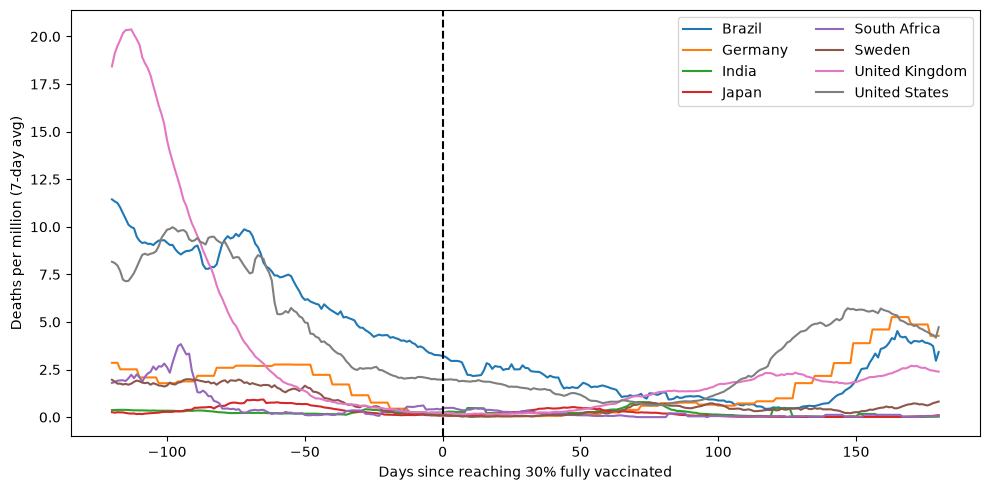

           date  total_deaths_per_million
8578 2023-06-30                 597.56354


In [2]:
# 1. Sensitivity: does the result change with a different threshold?
def before_after(thresh, window=90, lag=28):
    h = (vax[vax["people_fully_vaccinated_per_hundred"] >= thresh]
         .groupby("country")["date"].min())
    out = {}
    for c, t in h.items():
        d = win[win["country"] == c].set_index("date")["new_deaths_smoothed_per_million"]
        b = d.loc[t - pd.Timedelta(days=window): t - pd.Timedelta(days=1)].mean()
        a = d.loc[t + pd.Timedelta(days=lag): t + pd.Timedelta(days=lag + window - 1)].mean()
        out[c] = round((a / b - 1) * 100)
    return pd.Series(out)

sens = pd.DataFrame({f"{t}%": before_after(t) for t in [20, 30, 50]})
print(sens)

# 2. Event-study view: deaths relative to the day each country hit 30%
fig, ax = plt.subplots(figsize=(10, 5))
for c, t in hit.items():
    d = win[win["country"] == c].set_index("date")["new_deaths_smoothed_per_million"]
    rel = d.loc[t - pd.Timedelta(days=120): t + pd.Timedelta(days=180)]
    ax.plot((rel.index - t).days, rel.values, label=c)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Days since reaching 30% fully vaccinated")
ax.set_ylabel("Deaths per million (7-day avg)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

# 3. Japan sanity check: cumulative deaths per million by mid-2023
jp = sub[(sub["country"] == "Japan") & (sub["date"] <= "2023-06-30")]
print(jp.dropna(subset=["total_deaths_per_million"])
        .tail(1)[["date", "total_deaths_per_million"]])